Polinomijalna regresija sa fiksnim stepenom polinoma 4, ali uz dodatu L2 regularizaciju

Lambda = 0, loss = 1297.6785888671875, w = [-1.0388651   0.02449178  0.03575777 -0.14163706], bias = 0.2144937813282013
Lambda = 0.001, loss = 850.8148193359375, w = [-1.1497192  -0.03895133  0.10810976 -0.10479678], bias = 0.23645050823688507
Lambda = 0.01, loss = 864.830810546875, w = [-1.151498   -0.07893934  0.11272268 -0.08954046], bias = 0.2530459463596344
Lambda = 0.1, loss = 1056.666259765625, w = [-1.0182462  -0.0628425   0.03719313 -0.10732409], bias = 0.24611122906208038
Lambda = 1, loss = 1969.8289794921875, w = [-0.5306648  -0.02163865 -0.20916402 -0.14613801], bias = 0.20478703081607819
Lambda = 10, loss = 4230.96142578125, w = [-0.17208803 -0.02488411 -0.19093968 -0.05626456], bias = 0.07547777146100998
Lambda = 100, loss = 6496.29931640625, w = [-0.03032263 -0.00306674 -0.03940691  0.00028176], bias = -0.0030567150097340345


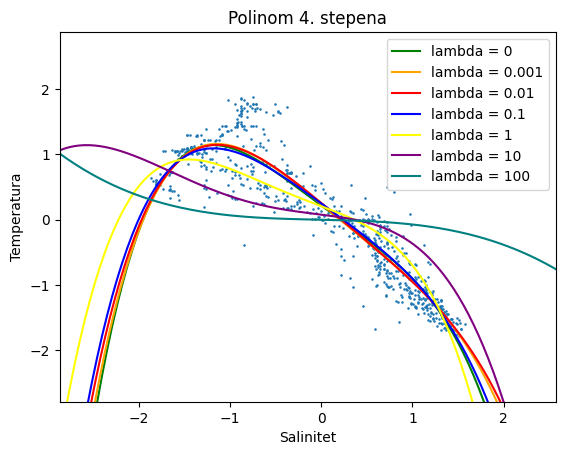

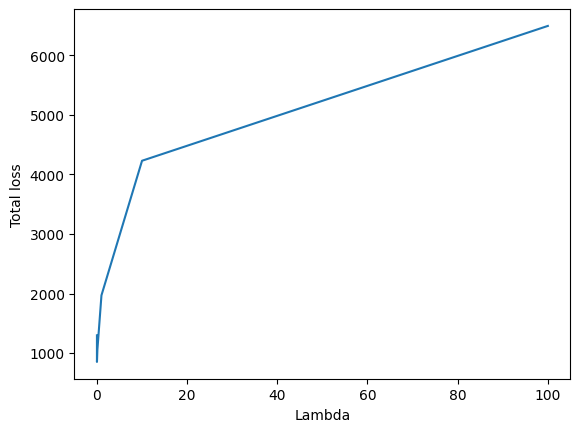

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


#Identican kod kao u 2a fajlu:
def create_feature_matrix(x,nb_features):
  tmp_features = []
  for deg in range(1, nb_features+1):
    tmp_features.append(np.power(x, deg))
  return np.column_stack(tmp_features)


filename = 'bottle.csv'
data = dict()

all_data = np.genfromtxt(filename, delimiter=',', usecols=(5,6),dtype='float32',invalid_raise=False)
filtered_data = all_data[~np.isnan(all_data).any(axis=1)]

data['x'] = filtered_data[:700,1]
data['y'] = filtered_data[:700,0]

nb_samples = len(data['x'])
indices = np.random.permutation(nb_samples)
data['x'] = data['x'][indices]
data['y'] = data['y'][indices]

data['x'] = (data['x'] - np.mean(data['x'], axis=0)) / np.std(data['x'], axis=0)
data['y'] = (data['y'] - np.mean(data['y'])) / np.std(data['y'])

min_x = np.min(data['x'])
max_x = np.max(data['x'])
min_y = np.min(data['y'])
max_y = np.max(data['y'])


#stepen polinoma 4
nb_features = 4
data['x'] = create_feature_matrix(data['x'], nb_features)

plt.scatter(data['x'][:,0], data['y'], s=0.7)
plt.title("Polinom 4. stepena")
plt.xlabel('Salinitet')
plt.ylabel('Temperatura')
col = 0
colours = ['green', 'orange', 'red', 'blue', 'yellow', 'purple', 'teal']



w = tf.Variable(tf.zeros(nb_features))
b = tf.Variable(0.0)

learning_rate = 0.001
nb_epochs = 10


#opet isti kod:
def prediction(x, w, b):
  w_col = tf.reshape(w, (nb_features,1))
  hyp = tf.add(tf.matmul(x, w_col), b)
  return hyp

#jedino u loss ubacujemo L2 regularizaciju:
def loss(x, y, w, b, lambd):
  pred = prediction(x, w, b)

  y_col = tf.reshape(y, (-1,1))
  loss = tf.reduce_mean(tf.square(pred - y_col))

  l2 = lambd * tf.reduce_mean(tf.square(w))
  loss_value = tf.add(loss, l2)

  return loss_value

def calc_grad(x,y,w,b, nb_features):
  with tf.GradientTape() as tape:
    loss_val = loss(x, y, w, b, nb_features)

  w_grad, b_grad = tape.gradient(loss_val, [w, b])

  return w_grad, b_grad, loss_val

def train_step(x, y, w, b, nb_features, adam):

  w_grad, b_grad, loss = calc_grad(x, y, w, b, nb_features)

  adam.apply_gradients(zip([w_grad, b_grad], [w, b]))

  return loss

def run_lambda(lambd):

  global col
  adam = tf.keras.optimizers.Adam(learning_rate = learning_rate)

  total_loss = 0

  for e in range(nb_epochs):

    for s in range(nb_samples):

      x = data['x'][s].reshape((1, nb_features))
      y = data['y'][s]

      curr_loss = train_step(x,y,w,b,lambd, adam)
      total_loss += curr_loss

  print(f'Lambda = {lambd}, loss = {total_loss}, w = {w.numpy()}, bias = {b.numpy()}')
  xs = create_feature_matrix(np.linspace(min_x-1, max_x+1, 200, dtype='float32'), nb_features)
  hyp_val = prediction(xs, w, b)
  plt.plot(xs[:, 0].tolist(), hyp_val.numpy().tolist(), color=colours[col], label=f'lambda = {lambd}')
  col+=1
  plt.xlim([min_x-1, max_x+1])
  plt.ylim([min_y-1, max_y+1])

  return total_loss

#pokrecemo za svako zadato lambda
losses=[]
lambdas = [0, 0.001, 0.01, 0.1, 1, 10 ,100]
for l in lambdas:
  lambda_loss = run_lambda(l)
  losses.append(lambda_loss)

#plotovanje zavisnosti troska od lambde
plt.legend()
plt.figure()
plt.plot(lambdas, losses)
plt.xlabel('Lambda')
plt.ylabel('Total loss')
plt.show()

#sa prvog grafika zaključujemo da su se vrednosti lambda od 0 do 0.1 ubedljivo najbolje pokazale
#ako pogledamo loss, najmanji je kod vrednosti lambda 0.001 i 0.01 te je zakljucak da su ove vrednosti
#za lambdu najbolji izbor

#To nam potvrdjuje i drugi grafik koji nam pokazuje da total loss raste sa rastom lambde